# Task 6 – Netflix Content Success Analytics Engine

**Goal:** build an end-to-end machine learning solution that studies content patterns and turns them into business insights.

## What I'm building (the whole pipeline)

```
raw data  ->  feature engineering  ->  several models  ->  compare & tune  ->  automated insights  ->  visual report  ->  saved model
```

## The first honest question: what does "success" mean here?

This dataset has **no views, no viewer ratings and no revenue**, so I can't measure success directly. Instead of pretending, I use a clear, defensible proxy:

> **A TV series is a "success" if it reached 2 or more seasons.**

Why this makes sense: a studio only keeps making a show when it is working, so multi-season shows are a reasonable stand-in for "this worked". It is only a proxy, and I'll point out its limits in the conclusion. I use TV series only, because movies have no equivalent signal (a movie has no seasons).

**The business question the engine answers:** *what do multi-season shows have in common, and can we predict which new shows are likely to go the distance?*

In [1]:
import re
import json
import shutil
import joblib
import platform
import warnings
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, roc_curve, f1_score, accuracy_score,
                             precision_score, recall_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

OUT_DIR = Path("task6_outputs")          # everything the pipeline produces is saved here
OUT_DIR.mkdir(exist_ok=True)

## Step 0 – Load the data and define "success"

I load the file, parse the dates, and keep the TV shows. Then I create the target column `success` (2+ seasons).

**One thing I have to be careful about:** a show released recently has had less time to earn a second season. To be fair, I **train only on shows released up to 2019**, and keep the 2020–2021 shows aside as "new content" that I'll score at the end, as a demo of how the engine would be used on fresh titles.

All titles: 8,790 | TV shows: 2,664
Learning set (released <= 2019): 1,913 shows, success rate 32.2%
New content (2020-2021)        : 751 shows


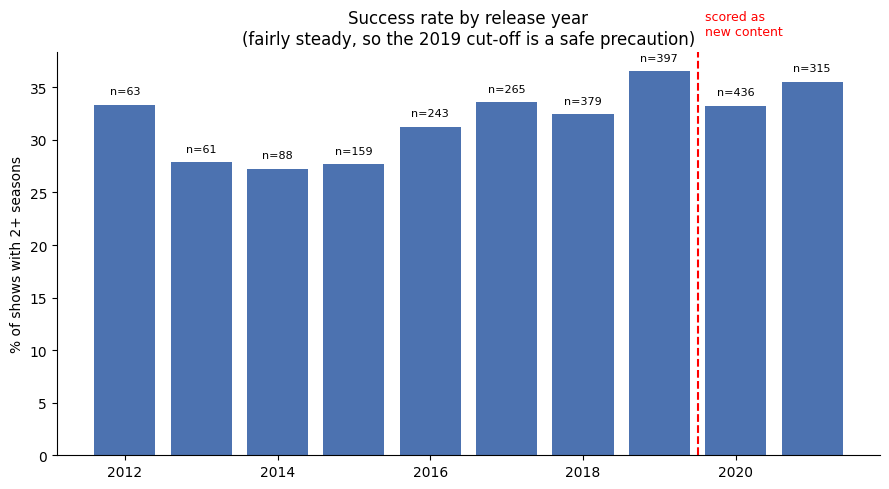

In [2]:
DATA_PATH = "Dataset.csv"      # change if your file is in another folder

df = pd.read_csv(DATA_PATH).drop_duplicates().reset_index(drop=True)
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%m/%d/%Y", errors="coerce")
df["duration_num"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")

def split_items(text):
    return [p.strip() for p in str(text).split(",") if p.strip()]

def simplify_genre(name):
    """'TV Dramas' and 'Dramas' mean the same thing -> 'Dramas'."""
    name = name.strip()
    if name in ("Movies", "TV Shows"):
        return "Other"
    name = re.sub(r"^TV\s+", "", name)
    return re.sub(r"\s+(Movies|TV Shows|TV)$", "", name)

tv = df[df["type"] == "TV Show"].copy().reset_index(drop=True)
tv["seasons"] = tv["duration_num"].astype(int)
tv["success"] = (tv["seasons"] >= 2).astype(int)
tv["country_main"] = tv["country"].apply(lambda s: split_items(s)[0] if split_items(s) else "Not Given")
tv["genre_list"] = tv["listed_in"].apply(lambda s: [simplify_genre(g) for g in split_items(s)])

history = tv[tv["release_year"] <= 2019].reset_index(drop=True)    # used for learning
recent = tv[tv["release_year"] >= 2020].reset_index(drop=True)     # "new content" to score later

print(f"All titles: {len(df):,} | TV shows: {len(tv):,}")
print(f"Learning set (released <= 2019): {len(history):,} shows, success rate {history['success'].mean():.1%}")
print(f"New content (2020-2021)        : {len(recent):,} shows")

# How does the success rate change with release year?
by_year = tv[tv["release_year"] >= 2012].groupby("release_year")["success"].agg(["mean", "count"])
fig, ax = plt.subplots()
ax.bar(by_year.index, by_year["mean"] * 100, color="#4c72b0")
for yr, row in by_year.iterrows():
    ax.text(yr, row["mean"] * 100 + 1, f"n={int(row['count'])}", ha="center", fontsize=8)
ax.axvline(2019.5, color="red", linestyle="--")
ax.text(2019.6, 40, "scored as\nnew content", color="red", fontsize=9)
ax.set_ylabel("% of shows with 2+ seasons")
ax.set_title("Success rate by release year\n(fairly steady, so the 2019 cut-off is a safe precaution)")
plt.tight_layout()
plt.show()

# Step 1 – Advanced feature engineering

Raw columns like `listed_in = "Crime TV Shows, International TV Shows"` aren't useful to a model as they are. I turn them into meaningful signals. The important design choice: **all of this lives inside one reusable class, `NetflixFeatureBuilder`, that is part of the pipeline.** That gives me three benefits:

1. **No data leakage.** Anything the builder *learns* (which genres are common, which countries are common) is learned only from the training rows, even during cross-validation.
2. **One-step reuse.** A brand-new show goes in as a raw row and comes out as a prediction, with no manual preparation.
3. **MLOps friendly.** The whole thing can be saved as one file and loaded later.

**Features it creates**

| Group | Features | Why it might matter |
|---|---|---|
| Genre | 20 genre flags, number of genres, "genre mainstream score" | Some genres sustain a series better than others |
| Geography | main country group, number of countries, international flag | Different markets produce different kinds of series |
| Audience | Kids / Family / Teens / Adults from the rating | Kids' series tend to run longer |
| Timing | release year, years until added, month added, Q4 flag | Release timing might matter |
| Market context | how many titles Netflix added that same month | A crowded month means more competition |
| Production | director credited | Series with a credited director are often different in kind |
| Title style | title length, word count, has a colon, has a number | Spin-offs and franchises often have a colon ("Narcos: Mexico") |

In [3]:
AUDIENCE_MAP = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "PG": "Family", "TV-PG": "Family",
    "PG-13": "Teens", "TV-14": "Teens",
    "R": "Adults", "TV-MA": "Adults", "NC-17": "Adults",
}

# Market context: how many titles (movies and shows) Netflix added in each (year, month)
monthly_supply = df.groupby([df["date_added"].dt.year, df["date_added"].dt.month]).size().to_dict()


class NetflixFeatureBuilder(BaseEstimator, TransformerMixin):
    """Turns raw Netflix columns into model-ready features.
    fit() learns only from the rows it is given, so there is no leakage."""

    def __init__(self, n_top_genres=20, min_country_count=30, monthly_supply=None):
        self.n_top_genres = n_top_genres
        self.min_country_count = min_country_count
        self.monthly_supply = monthly_supply

    @staticmethod
    def _main_country(text):
        items = split_items(text)
        return items[0] if items else "Not Given"

    def fit(self, X, y=None):
        genre_lists = X["listed_in"].apply(lambda s: [simplify_genre(g) for g in split_items(s)])
        counts = pd.Series([g for lst in genre_lists for g in lst]).value_counts()
        self.top_genres_ = counts.head(self.n_top_genres).index.tolist()
        self.genre_share_ = (counts / len(X)).to_dict()
        country_counts = X["country"].apply(self._main_country).value_counts()
        self.common_countries_ = set(country_counts[country_counts >= self.min_country_count].index)
        return self

    def transform(self, X):
        out = pd.DataFrame(index=X.index)
        supply = self.monthly_supply or {}

        # Timing
        added = pd.to_datetime(X["date_added"], errors="coerce")
        out["release_year"] = X["release_year"].astype(float)
        out["years_to_add"] = (added.dt.year.fillna(X["release_year"]) - X["release_year"]).clip(lower=0)
        out["month_added"] = added.dt.month.fillna(0)
        out["is_q4_added"] = (out["month_added"] >= 10).astype(int)
        out["month_supply"] = [supply.get((y, m), 0) for y, m in zip(added.dt.year, added.dt.month)]

        # Genres
        genre_lists = X["listed_in"].apply(lambda s: [simplify_genre(g) for g in split_items(s)])
        out["n_genres"] = genre_lists.apply(len)
        out["genre_mainstream"] = genre_lists.apply(
            lambda lst: np.mean([self.genre_share_.get(g, 0) for g in lst]) if lst else 0)
        for g in self.top_genres_:
            out["genre_" + g] = genre_lists.apply(lambda lst, g=g: int(g in lst))

        # Geography
        main = X["country"].apply(self._main_country)
        out["n_countries"] = X["country"].apply(lambda s: len([c for c in split_items(s) if c != "Not Given"]))
        out["is_international"] = (main != "United States").astype(int)
        out["country_group"] = main.where(main.isin(self.common_countries_), "Other")

        # Audience and production
        out["audience"] = X["rating"].map(AUDIENCE_MAP).fillna("Other")
        out["has_director"] = (X["director"].astype(str).str.strip().replace("", "Not Given") != "Not Given").astype(int)

        # Title style
        titles = X["title"].astype(str)
        out["title_len"] = titles.str.len()
        out["title_words"] = titles.str.split().apply(len)
        out["title_has_colon"] = titles.str.contains(":").astype(int)
        out["title_has_digit"] = titles.str.contains(r"\d").astype(int)
        return out


RAW_COLS = ["title", "director", "country", "date_added", "release_year", "rating", "listed_in"]
CATEGORICAL = ["country_group", "audience"]

def numeric_columns(frame):
    """Every engineered column that is not a category is numeric (a named function, so the model can be saved)."""
    return [c for c in frame.columns if c not in CATEGORICAL]

def make_pipeline(model):
    """Raw rows -> engineered features -> scaling/encoding -> model."""
    prep = ColumnTransformer([
        ("num", StandardScaler(), numeric_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CATEGORICAL),
    ])
    return Pipeline([("features", NetflixFeatureBuilder(monthly_supply=monthly_supply)),
                     ("prep", prep),
                     ("model", model)])

# A quick look at what the builder produces
demo = NetflixFeatureBuilder(monthly_supply=monthly_supply).fit(history[RAW_COLS]).transform(history[RAW_COLS])
print(f"Raw columns used: {len(RAW_COLS)}  ->  engineered features: {demo.shape[1]}")
demo.head(3).T

Raw columns used: 7  ->  engineered features: 36


,0,1,2
release_year,2018.0,2018.0,2018.0
years_to_add,0,0,0
month_added,6,6,5
is_q4_added,0,0,0
month_supply,78,78,97
n_genres,1,1,1
genre_mainstream,0.178254,0.178254,0.178254
genre_International,0,0,0
genre_Dramas,0,0,0
genre_Comedies,0,0,0


# Step 2 – Build multiple machine learning models

I split the learning set 80/20 (stratified, so both parts keep the same share of successes). I **never touch the 20% test set until the end**, so it gives an honest final score.

I compare four models, from simple to powerful:
- **Logistic Regression** – simple, fast, easy to explain.
- **Decision Tree** – learns readable if/else rules (kept shallow so it doesn't memorize).
- **Random Forest** – many trees voting together.
- **Gradient Boosting** – trees built one after another, each fixing the previous one's mistakes.

About 1 in 3 shows is a success, so accuracy alone can mislead (always guessing "no" would score about 68%). My main score is **ROC-AUC**: the chance that the model ranks a real success above a non-success. 0.5 is a coin flip, 1.0 is perfect.

In [4]:
X = history[RAW_COLS]
y = history["success"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} | Test: {len(X_test)} | success rate train/test: {y_train.mean():.1%} / {y_test.mean():.1%}")

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy", "precision": "precision", "recall": "recall"}

cv_rows = {}
for name, model in models.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {m: res[f"test_{m}"].mean() for m in scoring}

cv_table = pd.DataFrame(cv_rows).T.round(3)
print("5-fold cross-validation on the training data (the feature builder is re-fitted inside every fold):")
cv_table

Train: 1530 | Test: 383 | success rate train/test: 32.2% / 32.1%
5-fold cross-validation on the training data (the feature builder is re-fitted inside every fold):


,roc_auc,f1,accuracy,precision,recall
Logistic Regression,0.753,0.598,0.696,0.523,0.702
Decision Tree,0.671,0.525,0.631,0.452,0.633
Random Forest,0.751,0.578,0.720,0.563,0.594
Gradient Boosting,0.742,0.471,0.712,0.582,0.398


# Step 3 – Compare model performance and optimize

The table above shows the models are fairly close, so I **tune the two strongest tree models** with `RandomizedSearchCV`. It tries random combinations of settings (number of trees, depth, learning rate...) and scores each with cross-validation on the training data only.

Then I evaluate **everything once on the untouched test set**, together with a "no model" reference that guesses randomly (AUC 0.5).

In [5]:
search_space = {
    "Random Forest": {
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [None, 6, 10, 15],
        "model__min_samples_leaf": [1, 3, 5, 10],
        "model__max_features": ["sqrt", 0.3, 0.5],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.7, 0.85, 1.0],
    },
}

tuned = {}
for name, space in search_space.items():
    search = RandomizedSearchCV(make_pipeline(models[name]), space, n_iter=12, cv=cv,
                                scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=1)
    search.fit(X_train, y_train)
    tuned[name + " (tuned)"] = search
    print(f"{name}: CV AUC {cv_table.loc[name, 'roc_auc']:.3f} -> {search.best_score_:.3f} after tuning")
    print("   best settings:", {k.replace('model__', ''): v for k, v in search.best_params_.items()})

Random Forest: CV AUC 0.751 -> 0.751 after tuning
   best settings: {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}
Gradient Boosting: CV AUC 0.742 -> 0.756 after tuning
   best settings: {'subsample': 0.85, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.03}


In [6]:
# Evaluate everything once on the held-out test set
fitted = {}
for name, model in models.items():
    fitted[name] = make_pipeline(model).fit(X_train, y_train)
for name, search in tuned.items():
    fitted[name] = search.best_estimator_

test_rows = {}
for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    test_rows[name] = {"ROC-AUC": roc_auc_score(y_test, proba), "F1": f1_score(y_test, pred),
                       "Accuracy": accuracy_score(y_test, pred),
                       "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred)}
test_table = pd.DataFrame(test_rows).T.round(3).sort_values("ROC-AUC", ascending=False)
test_table.loc["Random guessing"] = [0.5, np.nan, 1 - y_test.mean(), np.nan, np.nan]
test_table

,ROC-AUC,F1,Accuracy,Precision,Recall
Random Forest,0.822,0.629,0.760000,0.624,0.634
Gradient Boosting (tuned),0.819,0.615,0.781000,0.705,0.545
Gradient Boosting,0.815,0.562,0.768000,0.712,0.463
Random Forest (tuned),0.813,0.621,0.739000,0.582,0.667
Logistic Regression,0.810,0.643,0.734000,0.564,0.748
Decision Tree,0.760,0.626,0.728000,0.561,0.707
Random guessing,0.500,NaN,0.678851,NaN,NaN


**How to read this table:** the top models are within about 0.01 of each other, and with only 383 test shows that gap is inside the noise, so I don't claim one is truly better. I chose the final model by its **cross-validated** score (a steadier measure than one small test set). Notice also that the test AUC is a bit higher than the cross-validation AUC. That is normal luck with a small test set, so the honest summary is "roughly 0.75 to 0.8".

Final model: Gradient Boosting (tuned) | test ROC-AUC = 0.819
Top 10% of shows by predicted score: 76% actually reached 2+ seasons vs 32% overall (2.4x lift)


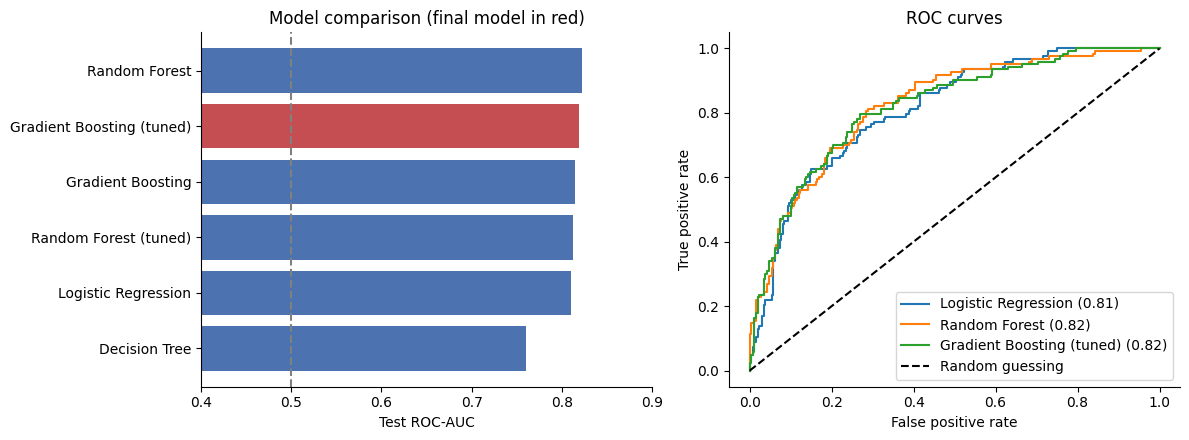

In [7]:
# Pick the final model: the tuned model with the best cross-validated AUC
best_name = max(tuned, key=lambda n: tuned[n].best_score_)
final_model = fitted[best_name]
final_proba = final_model.predict_proba(X_test)[:, 1]
final_auc = roc_auc_score(y_test, final_proba)
print("Final model:", best_name, f"| test ROC-AUC = {final_auc:.3f}")

# A business-friendly measure: if we pick the top 10% of shows the model likes most, how many succeed?
order = np.argsort(-final_proba)
top_n = max(1, int(0.10 * len(order)))
top_rate = y_test.values[order[:top_n]].mean()
base_rate = y_test.mean()
lift = top_rate / base_rate
print(f"Top 10% of shows by predicted score: {top_rate:.0%} actually reached 2+ seasons vs {base_rate:.0%} overall ({lift:.1f}x lift)")

# Charts: comparison and ROC curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_table = test_table.drop("Random guessing")["ROC-AUC"].sort_values()
axes[0].barh(plot_table.index, plot_table.values, color=["#c44e52" if n == best_name else "#4c72b0" for n in plot_table.index])
axes[0].axvline(0.5, color="gray", linestyle="--")
axes[0].set_xlim(0.4, 0.9); axes[0].set_xlabel("Test ROC-AUC"); axes[0].set_title("Model comparison (final model in red)")
for name in ["Logistic Regression", "Random Forest", best_name]:
    fpr, tpr, _ = roc_curve(y_test, fitted[name].predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} ({test_table.loc[name, 'ROC-AUC']:.2f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curves"); axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

## What drives success? (permutation importance)

To see **which information the model really relies on**, I shuffle one raw column at a time in the test set and measure how much the score drops. A big drop means the column matters. This works on any model, which is why I prefer it to a model-specific importance chart.

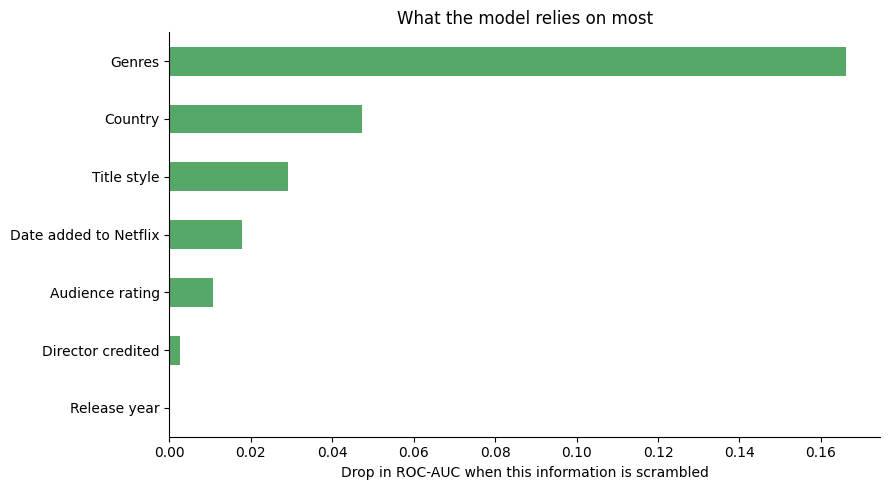

,0
Genres,0.1662
Country,0.0473
Title style,0.0291
Date added to Netflix,0.0178
Audience rating,0.0107
Director credited,0.0026
Release year,0.0002


In [8]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE)

friendly = {"listed_in": "Genres", "country": "Country", "rating": "Audience rating",
            "release_year": "Release year", "date_added": "Date added to Netflix",
            "director": "Director credited", "title": "Title style"}
drivers = pd.Series(perm.importances_mean, index=[friendly[c] for c in X_test.columns]).sort_values(ascending=False)

drivers.sort_values().plot(kind="barh", color="#55a868")
plt.xlabel("Drop in ROC-AUC when this information is scrambled")
plt.title("What the model relies on most")
plt.tight_layout()
plt.show()
drivers.round(4)

**Reading the chart:** genres matter most by a wide margin, then country. "Title style" ranks third mostly because of title *length*: in this data, shorter titles go with longer-running shows (about 37% for the shortest quarter of titles vs 26% for the longest). Many long-running franchises have short, brand-like names. That is a correlation, not a tip to shorten titles.

# Step 4 – Generate automated insights

This is the "business intelligence" part. Instead of me reading charts and writing sentences by hand, a function looks at the data and the model and **writes the insights automatically**. If you give it new data, the sentences update themselves.

It reports patterns in the data (which countries, genres, audiences and months go with multi-season shows) and combines them with what the model learned. Only groups with enough shows are mentioned, so tiny groups don't create misleading headlines.

A note on wording: these are *associations*, not proof of cause. A genre being linked with longer runs doesn't mean adding that genre will make a show last.

In [9]:
def rate_table(frame, key, min_count):
    table = frame.groupby(key)["success"].agg(rate="mean", n="count")
    return table[table["n"] >= min_count].sort_values("rate", ascending=False)

def generate_insights(data, drivers, auc, cv_auc, lift, top_rate, base_rate):
    insights = []
    n, base = len(data), data["success"].mean()
    insights.append(f"Overall, {base:.0%} of the {n:,} TV shows released through 2019 reached 2 or more seasons.")

    # Country
    country = rate_table(data, "country_main", 30)
    c_hi, c_lo = country.index[0], country.index[-1]
    insights.append(f"Country is strongly linked with success: {c_hi} shows reach multiple seasons {country.iloc[0]['rate']:.0%} of the time, "
                    f"versus {country.iloc[-1]['rate']:.0%} for {c_lo} (countries with 30+ shows).")

    # Audience
    data = data.copy()
    data["audience"] = data["rating"].map(AUDIENCE_MAP).fillna("Other")
    aud = rate_table(data[data["audience"] != "Other"], "audience", 30)
    insights.append(f"By audience, {aud.index[0]} content does best ({aud.iloc[0]['rate']:.0%}) and {aud.index[-1]} content lowest ({aud.iloc[-1]['rate']:.0%}).")

    # Genres
    genre_rows = data.explode("genre_list").rename(columns={"genre_list": "genre"})
    genre = rate_table(genre_rows, "genre", 40)
    best3 = ", ".join(f"{g} ({r:.0%})" for g, r in genre["rate"].head(3).items())
    worst3 = ", ".join(f"{g} ({r:.0%})" for g, r in genre["rate"].tail(3).items())
    insights.append(f"Genres most associated with multi-season shows: {best3}. Least associated: {worst3}.")

    # Director
    d = data.groupby(data["director"] != "Not Given")["success"].mean()
    insights.append(f"Series with a credited director reach 2+ seasons {d.loc[True]:.0%} of the time, versus {d.loc[False]:.0%} for series without one.")

    # Timing
    data["month_added"] = data["date_added"].dt.month
    month = rate_table(data.dropna(subset=["month_added"]), "month_added", 60)
    names = {i + 1: m for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                              "August", "September", "October", "November", "December"])}
    insights.append(f"Shows added to Netflix in {names[int(month.index[0])]} have the highest success rate ({month.iloc[0]['rate']:.0%}) "
                    f"and in {names[int(month.index[-1])]} the lowest ({month.iloc[-1]['rate']:.0%}); this is a weak pattern, so treat it cautiously.")

    # Model
    top3 = ", ".join(drivers.index[:3])
    insights.append(f"The model separates successes from non-successes with ROC-AUC {auc:.2f} on the test set and {cv_auc:.2f} in cross-validation (0.5 = guessing). "
                    f"Its three most important information sources are: {top3}.")
    insights.append(f"If we shortlist the top 10% of shows by predicted score, {top_rate:.0%} reach 2+ seasons versus {base_rate:.0%} overall ({lift:.1f}x better than picking at random).")

    # Recommendations (hedged on purpose)
    recs = [
        "Use the score as a screening tool: shows scoring in the top tier deserve a closer look, but it is not a replacement for editorial judgement.",
        f"Pay attention to audience and market: {aud.index[0]} content and {c_hi}-produced series show the strongest staying power in this catalog.",
        "Collect real performance data (views, completion rate, viewer ratings). It would replace the 2+ seasons proxy and likely lift accuracy a lot.",
    ]
    return insights, recs

insights, recommendations = generate_insights(history, drivers, final_auc, tuned[best_name].best_score_, lift, top_rate, base_rate)

print("AUTOMATED INSIGHTS")
for i, text in enumerate(insights, 1):
    print(f"{i}. {text}")
print("\nRECOMMENDATIONS")
for text in recommendations:
    print("-", text)

AUTOMATED INSIGHTS
1. Overall, 32% of the 1,913 TV shows released through 2019 reached 2 or more seasons.
2. Country is strongly linked with success: Canada shows reach multiple seasons 64% of the time, versus 2% for Taiwan (countries with 30+ shows).
3. By audience, Kids content does best (48%) and Family content lowest (25%).
4. Genres most associated with multi-season shows: Teen (56%), Sci-Fi & Fantasy (52%), Action & Adventure (50%). Least associated: Docuseries (15%), Romantic (14%), Science & Nature (13%).
5. Series with a credited director reach 2+ seasons 21% of the time, versus 33% for series without one.
6. Shows added to Netflix in July have the highest success rate (43%) and in October the lowest (24%); this is a weak pattern, so treat it cautiously.
7. The model separates successes from non-successes with ROC-AUC 0.82 on the test set and 0.76 in cross-validation (0.5 = guessing). Its three most important information sources are: Genres, Country, Title style.
8. If we shor

## Using the engine on new content

Two demos of the pipeline at work on raw rows:

1. **Score the 2020–2021 shows** that were kept aside, and list the ones the engine rates most likely to run for multiple seasons. (For these shows the "seasons so far" column is already known, but they are too recent to be a fair test, so treat that column as a curiosity, not as a verdict.)
2. **What-if scorer:** type in the details of an imaginary show and get its score. This is exactly what a business user would do with a pitch.

In [10]:
recent = recent.copy()
recent["success_probability"] = final_model.predict_proba(recent[RAW_COLS])[:, 1]
top_recent = (recent.sort_values("success_probability", ascending=False)
                    [["title", "country_main", "rating", "listed_in", "success_probability", "seasons"]]
                    .head(10).reset_index(drop=True))
top_recent["success_probability"] = top_recent["success_probability"].round(2)
print("Top 10 recent shows by predicted chance of running 2+ seasons:")
display(top_recent)

Top 10 recent shows by predicted chance of running 2+ seasons:


,title,country_main,rating,listed_in,success_probability,seasons
0,The Flash,United States,TV-14,"Crime TV Shows, TV Action & Adventure, TV Sci-...",0.91,7
1,Schitt's Creek,Canada,TV-MA,TV Comedies,0.90,6
2,Wynonna Earp,Canada,TV-MA,"International TV Shows, TV Action & Adventure,...",0.89,4
3,Johnny Test,United States,TV-Y7,"Kids' TV, TV Comedies",0.89,1
4,We the People,United States,TV-Y7,Kids' TV,0.88,1
5,Dogs,United States,TV-PG,Docuseries,0.88,2
6,Atypical,United States,TV-14,"TV Comedies, TV Dramas, Teen TV Shows",0.87,4
7,The Hollow,Canada,TV-Y7,"Kids' TV, TV Thrillers",0.87,2
8,Oh Yuck,Canada,TV-G,"Kids' TV, TV Comedies",0.87,1
9,Mighty Express,United States,TV-Y,Kids' TV,0.87,4


In [11]:
def score_new_show(title, country, rating, genres, release_year=2021, director="Not Given", date_added="2021-09-01"):
    """Return the engine's estimated chance that a new show reaches 2+ seasons."""
    row = pd.DataFrame([{"title": title, "director": director, "country": country,
                         "date_added": pd.Timestamp(date_added), "release_year": release_year,
                         "rating": rating, "listed_in": genres}])
    return float(final_model.predict_proba(row)[0, 1])

pitches = [
    ("Little Explorers", "United States", "TV-Y7", "Kids' TV, TV Comedies"),
    ("Midnight Files", "United States", "TV-MA", "Crime TV Shows, TV Dramas"),
    ("Silent Harbor", "South Korea", "TV-14", "International TV Shows, Romantic TV Shows, TV Dramas"),
    ("Cooking Duel", "United Kingdom", "TV-PG", "Reality TV"),
]
what_if = pd.DataFrame([{"Pitch": t, "Country": c, "Rating": r, "Genres": g, "Success score": round(score_new_show(t, c, r, g), 2)}
                        for t, c, r, g in pitches])
what_if

,Pitch,Country,Rating,Genres,Success score
0,Little Explorers,United States,TV-Y7,"Kids' TV, TV Comedies",0.72
1,Midnight Files,United States,TV-MA,"Crime TV Shows, TV Dramas",0.62
2,Silent Harbor,South Korea,TV-14,"International TV Shows, Romantic TV Shows, TV ...",0.11
3,Cooking Duel,United Kingdom,TV-PG,Reality TV,0.47


# Step 5 – Present the findings through a visual report

One dashboard that tells the whole story on a single page: how the catalog grew, which countries and genres go with multi-season shows, how the models compare, how good the final model is, and what it relies on. It is saved as an image so it can go straight into a presentation.

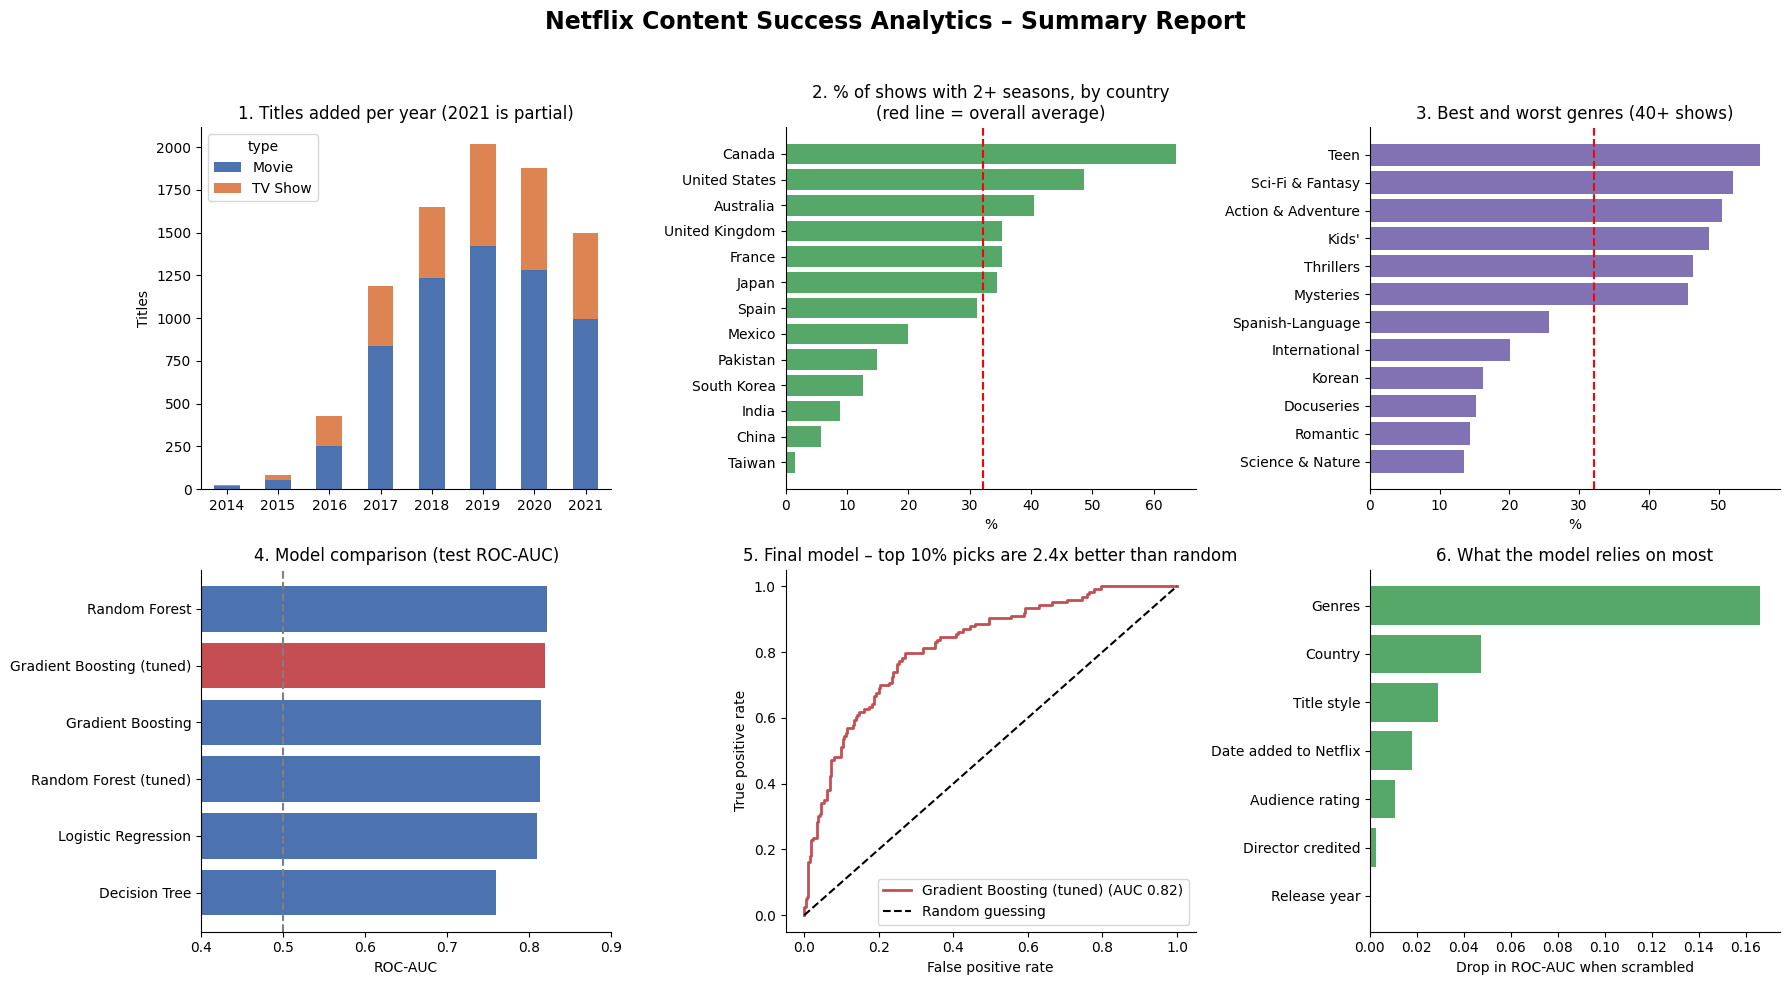

Saved: task6_outputs/netflix_success_report.png


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Netflix Content Success Analytics – Summary Report", fontsize=17, fontweight="bold")

# 1. Catalog growth by type
growth = df.dropna(subset=["date_added"]).groupby([df["date_added"].dt.year, "type"]).size().unstack(fill_value=0)
growth = growth[growth.index >= 2014]
growth.plot(kind="bar", stacked=True, ax=axes[0, 0], color=["#4c72b0", "#dd8452"], rot=0)
axes[0, 0].set_title("1. Titles added per year (2021 is partial)"); axes[0, 0].set_xlabel(""); axes[0, 0].set_ylabel("Titles")

# 2. Success rate by country
country = rate_table(history, "country_main", 30)["rate"].sort_values()
axes[0, 1].barh(country.index, country.values * 100, color="#55a868")
axes[0, 1].axvline(history["success"].mean() * 100, color="red", linestyle="--")
axes[0, 1].set_title("2. % of shows with 2+ seasons, by country\n(red line = overall average)"); axes[0, 1].set_xlabel("%")

# 3. Success rate by genre
genre_rows = history.explode("genre_list").rename(columns={"genre_list": "genre"})
genre = rate_table(genre_rows, "genre", 40)["rate"]
genre = pd.concat([genre.head(6), genre.tail(6)]).drop_duplicates().sort_values()
axes[0, 2].barh(genre.index, genre.values * 100, color="#8172b3")
axes[0, 2].axvline(history["success"].mean() * 100, color="red", linestyle="--")
axes[0, 2].set_title("3. Best and worst genres (40+ shows)"); axes[0, 2].set_xlabel("%")

# 4. Model comparison
plot_table = test_table.drop("Random guessing")["ROC-AUC"].sort_values()
axes[1, 0].barh(plot_table.index, plot_table.values, color=["#c44e52" if n == best_name else "#4c72b0" for n in plot_table.index])
axes[1, 0].axvline(0.5, color="gray", linestyle="--"); axes[1, 0].set_xlim(0.4, 0.9)
axes[1, 0].set_title("4. Model comparison (test ROC-AUC)"); axes[1, 0].set_xlabel("ROC-AUC")

# 5. ROC curve of the final model
fpr, tpr, _ = roc_curve(y_test, final_proba)
axes[1, 1].plot(fpr, tpr, color="#c44e52", linewidth=2, label=f"{best_name} (AUC {final_auc:.2f})")
axes[1, 1].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[1, 1].set_title(f"5. Final model – top 10% picks are {lift:.1f}x better than random")
axes[1, 1].set_xlabel("False positive rate"); axes[1, 1].set_ylabel("True positive rate"); axes[1, 1].legend(loc="lower right")

# 6. What the model relies on
d = drivers.sort_values()
axes[1, 2].barh(d.index, d.values, color="#55a868")
axes[1, 2].set_title("6. What the model relies on most"); axes[1, 2].set_xlabel("Drop in ROC-AUC when scrambled")

plt.tight_layout(rect=[0, 0, 1, 0.96])
report_path = OUT_DIR / "netflix_success_report.png"
fig.savefig(report_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", report_path)

# MLOps fundamentals – save, version and re-load the model

A model that only lives inside a notebook can't be used by anyone else. Here I do the basic things a real project needs:

- **Save the whole pipeline** (feature builder + preprocessing + model) as one file.
- **Save metadata:** when it was trained, library versions, data size and scores. Six months from now this answers "which model is this, and how good was it?".
- **Save the insights and scored titles** so the results can be shared without re-running anything.
- **Reload and check:** the reloaded model must give *exactly* the same predictions. This is a simple reproducibility test.

In [13]:
joblib.dump(final_model, OUT_DIR / "success_model.joblib")

metadata = {
    "model": best_name,
    "trained_on": dt.datetime.now().strftime("%Y-%m-%d %H:%M"),
    "success_definition": "TV show reached 2 or more seasons (proxy; the dataset has no viewership data)",
    "training_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "test_roc_auc": round(float(final_auc), 4),
    "top10pct_lift": round(float(lift), 2),
    "python": platform.python_version(), "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__,
}
(OUT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))
(OUT_DIR / "insights.txt").write_text(
    "AUTOMATED INSIGHTS\n" + "\n".join(f"{i}. {t}" for i, t in enumerate(insights, 1)) +
    "\n\nRECOMMENDATIONS\n" + "\n".join(f"- {t}" for t in recommendations))
top_recent.to_csv(OUT_DIR / "top_recent_shows.csv", index=False)
test_table.to_csv(OUT_DIR / "model_comparison.csv")

# Reload and verify
reloaded = joblib.load(OUT_DIR / "success_model.joblib")
same = np.allclose(reloaded.predict_proba(X_test)[:, 1], final_proba)
print("Reloaded model gives identical predictions:", same)
print("\nFiles created in", OUT_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print("  -", f.name)

Reloaded model gives identical predictions: True

Files created in /content/task6_outputs
  - insights.txt
  - model_comparison.csv
  - model_metadata.json
  - netflix_success_report.png
  - success_model.joblib
  - top_recent_shows.csv


In [14]:
# Optional: in Google Colab this downloads everything above as one zip. On your own computer it just prints a note.
try:
    from google.colab import files
    shutil.make_archive("task6_outputs", "zip", OUT_DIR)
    files.download("task6_outputs.zip")
except ImportError:
    print("Not running in Colab - the results are in the folder:", OUT_DIR.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusion

**What I built:** an end-to-end pipeline that takes raw Netflix rows, engineers about 40 features, compares four models, tunes the best two, explains what drives success in plain-English insights, scores new shows, draws a one-page visual report, and saves the whole thing as a reusable model with metadata.

**What I found:** whether a series reaches multiple seasons is clearly linked with where it was made, who it is for and its genre. The final model clearly beats random guessing (see the ROC-AUC in the tables above), and the shows it rates most highly succeed far more often than average (see the lift figure). The signal is real but modest: about 0.75 ROC-AUC in cross-validation and about 0.82 on the test set (the gap is normal luck with a small test set), which is what I would expect from catalog data without viewing numbers.

**Limitations I want to be upfront about**
- **"Success" is a proxy.** Seasons on Netflix are not the same as renewals. Licensed shows often arrive with several seasons already, so some "successes" reflect the original broadcaster, not Netflix.
- **Movies are excluded** because there is no equivalent signal for them.
- **Correlation is not causation.** The insights describe patterns, not recipes.
- **Small data.** About 1,900 shows are used for learning, so results can shift a little with a different split.

**What I'd do next:** replace the proxy with real viewing data (views, completion rate, viewer scores), add plot descriptions as text features, and monitor the model over time to catch drift, which is the next step in MLOps.